# **Building a Random Forest Classifier**

In [ ]:
import pandas as pd
df= pd.read_csv("churn-bigml-20.csv")

Imported pandas so I will be able to work on the table in python

In [ ]:
df["Churn"]= df["Churn"].astype(int)

changes the value of Churn to an interger where False is 0 and True is 1 and saves it back into the churn array.

In [ ]:
df["International plan"] = df["International plan"].map({"No": 0, "Yes": 1})
df["Voice mail plan"] = df["Voice mail plan"].map({"No": 0, "Yes": 1})

When I checked through the dataset saw that there were still some colums that were not in numbers
so I changed them from "object" to integers
their values were No and Yes so I changed No to 0 and Yes to 1 because mathematical function can't be performed on objects

In [ ]:
X = df.drop(["Churn", "State", "Area code", "Total day minutes", "Total eve minutes", "Total night minutes", "Total intl minutes"], axis=1)
y = df["Churn"]

dropped the Churn because that's the target,

 also dropped the state cause it not actually a value used to get the target it is just a piece of information about each customer

dropped Area code because it is only 3 numbers and it acts like a label rather than an amount

and four minutes were dropped because The relationship between the minutes and the charge column are almost perfect because the total day minutes is multiplied by a fixed amount to get the total charge. So we can dropped the total day minutes because they mean almost the same thing.


All of this gives back a new tabel and is stored as "X"

Saved the target in "y"

The shape of X now is still 667 customers but the column now is 13.

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X.shape, X_train.shape, X_test.shape)
print(y_train.sum(), y_test.sum())

(667, 13) (533, 13) (134, 13)
76 19


Here a spilittig tool is imported then I cut the X and y into train dataset and test dataset.
My test dataset size is 20% of  the whole dataset
made my randon state 42 so that it is repeatable.
Also made stratify=y so that we can have a reasonable number of each of the value of y in the train and also the test dataset(both set are about 14% churners, the same share as the full data).

Now the shape of X,X_train,X_test can be seen and we added the value of all the y_train and the y_test since we changed them to integer where leave(churn) is 1 and stay is 0 and for y_train we have 76 which means the total number of people leaving are 76 and for y_test we have 19 which also means the total number of people leaving for the test data is 19.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train,y_train)
y_pred = rf.predict(X_test)

ensemble is sklearn section for methods that combine many models, and a random forest is part.

RandomForestClassifier(random...) creates a foreat with the default settings: 100 trees and each of those tree grows without a depyh limit. it was set to arandom state of 42 which makes it repeatable

.fit.. grows all the trees on the training customers

.predict.. runs every test customer through all the 100 trees and takes the majority vote.

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score
print(rf.score(X_train, y_train))
print(accuracy_score(y_test, y_pred))

1.0
0.9253731343283582


rf.score... is accuracy on the training customers and accuarcy_score.. is the accuracy on the test customers

The accuracy on the training customer is 1 which means the forest memorised them. but because of the tree vote, the odd mistakes cancels out and the test accuracy was up to 0.925.

In [ ]:
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))
roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])

[[115   0]
 [ 10   9]]
              precision    recall  f1-score   support

           0       0.92      1.00      0.96       115
           1       1.00      0.47      0.64        19

    accuracy                           0.93       134
   macro avg       0.96      0.74      0.80       134
weighted avg       0.93      0.93      0.91       134



np.float64(0.9123569794050344)

The confusion matrix shows rows as real outcomes and columns as guesses, the report gives precisio n,recall f1 score for each class, predict_proba(..) gives each customer's probability of leaving aND ROC_AUC_SCORE turns it into the auc

The confusion matrix shows that 115 loyal cutomer were correctly called loyal and 9 out of 19 churners were flagged and 10 churners were missed

Precision(for churn) was1.00 the model flagged exactly 9 customers and they all left indeed that means there was no false alarm

Recal(for churn) was 0.47 the model only flagged 9 out of 19 churners

As we know f1 blends both the precision and the  recall

 and the accuracy was about 0.91

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

imports the tools  that sets up 5 folds .  Stratified means each fold keeps the same share of churners , so that no fold ends up with almost none. shuffle= true  mixes the rows before cutting an d random... makes it repeatable

In [ ]:
for metric in ["accuracy", "f1", "roc_auc"]:
    scores = cross_val_score(RandomForestClassifier(random_state=42), X_train, y_train, cv=cv, scoring=metric)
    print(metric, scores.round(3), scores.mean().round(3), scores.std().round(3))

accuracy [0.916 0.897 0.897 0.915 0.906] 0.906 0.008
f1 [0.64  0.476 0.522 0.571 0.5  ] 0.542 0.058
roc_auc [0.918 0.893 0.926 0.858 0.866] 0.892 0.027


The loop runs once for each metric. cross_val_score(...) does the whole rotation for me. I gave it a fresh forest, the training inputs and answers, the cv setup, and the scoring measure, and it returns five scores, one per fold.


In [ ]:
from sklearn.model_selection import GridSearchCV
param_grid = {"n_estimators": [50, 100, 200],"max_depth":[3, 5, 10, None]}

GridSearchCV is the tool that runs the search.
param_grid is a dictionary: each name on the left is a setting, and the list on the right holds the values to try

In [ ]:
grid =GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=cv, scoring="f1", n_jobs=-1)

In [ ]:
grid.fit(X_train, y_train)
print(grid.best_params_)
print(grid.best_score_)


{'max_depth': 10, 'n_estimators': 50}
0.563948051948052


.fit(...) runs the whole search: 12 combinations × 5 folds = 60 trainings, which takes about a minute. It uses only the training data, so the test set stays untouched.
best_params_ is the winning combination, and best_score_ is its average cross-validated F1

In [ ]:
results = pd.DataFrame(grid.cv_results_)
results[["param_max_depth", "param_n_estimators", "mean_test_score", "std_test_score"]].sort_values("mean_test_score", ascending=False)

,param_max_depth,param_n_estimators,mean_test_score,std_test_score
6,10,50,0.563948,0.061100
9,None,50,0.549145,0.056009
10,None,100,0.541872,0.058267
7,10,100,0.534416,0.064422
11,None,200,0.521325,0.046001
8,10,200,0.486524,0.036181
3,5,50,0.425081,0.085072
4,5,100,0.389825,0.064835
5,5,200,0.350618,0.067576
1,3,100,0.073529,0.060097


This holds the score for every combination and turns it into a table.

In [ ]:
best_rf = grid.best_estimator_
y_pred_best = best_rf.predict(X_test)
print(classification_report(y_test, y_pred_best))
print(confusion_matrix(y_test, y_pred_best))
roc_auc_score(y_test, best_rf.predict_proba(X_test)[:, 1])

              precision    recall  f1-score   support

           0       0.92      1.00      0.96       115
           1       1.00      0.47      0.64        19

    accuracy                           0.93       134
   macro avg       0.96      0.74      0.80       134
weighted avg       0.93      0.93      0.91       134

[[115   0]
 [ 10   9]]


np.float64(0.9)

This checks the winner of the test set.

This is exactly the same result as the default forest on the test set (an AUC of 0.90 versus 0.91 aside). Tuning improved the cross-validated F1 only a little (from 0.54 to 0.56), and it didn’t change the test outcome.

In [ ]:
import matplotlib.pyplot as plt
importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.round(3))

Total day charge          0.254
Customer service calls    0.126
Total eve charge          0.125
Total intl charge         0.070
Total night charge        0.063
Total day calls           0.060
Total eve calls           0.056
Account length            0.056
Total night calls         0.050
International plan        0.047
Total intl calls          0.042
Number vmail messages     0.034
Voice mail plan           0.018
dtype: float64


best_rf.feature_importances_ is a list with one number per column, in the same order as the columns in X. A bigger number means the forest relied on that column more.
pd.Series(..., index=X.columns) attaches the column names to the numbers, so you can tell which is which.
.sort_values(ascending=False) puts the biggest first. .round(3) keeps three decimals, and print(...) shows the result.

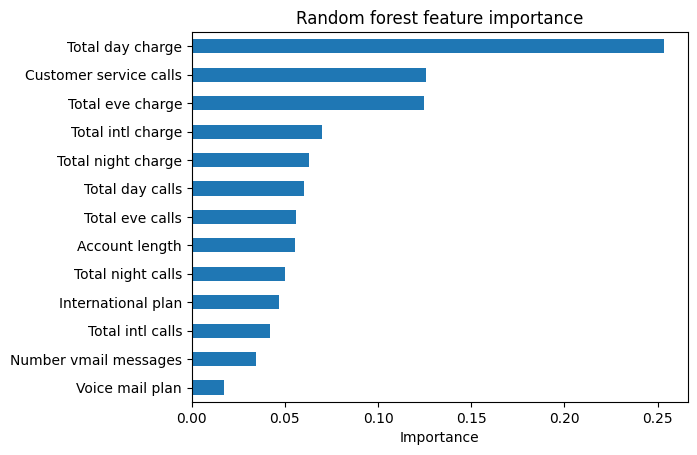

In [ ]:
importances.sort_values().plot(kind="barh")
plt.xlabel("Importance")
plt.title("Random forest feature importance")
plt.show()

This sorts from the samllest to biggest because the horizontal bar chart draw the first item at the bottom so the biggest ends up at the top


Total day charge leads by a wide margin (0.25). Daytime usage separates leavers from stayers better than any other column, so the trees ask about it most often and early.

Customer service calls and evening charge come next (about 0.125 each).





In [ ]:
from sklearn.inspection import permutation_importance
perm = permutation_importance(best_rf, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=42)
pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False).round(3)

,0
Total day charge,0.191
Customer service calls,0.131
Total eve charge,0.063
International plan,0.042
Total intl calls,0.010
Number vmail messages,0.008
Account length,0.007
Total intl charge,0.005
Voice mail plan,0.004
Total night charge,0.000


take one column in the test data and shuffle its values, so that column no longer carries real information. Then see how much the model's AUC drops. A big drop means the model needed that column.